# Analisis SARIMAX Neraca Beras Kabupaten Bojonegoro 2021–2023
**Metode Box-Jenkins** · data BPS Kabupaten Bojonegoro · materi Analisis Deret Waktu Bab 5

Model utama adalah **SARIMAX** untuk ln(produksi beras) dengan **variabel eksogen X = ln(luas panen)**,
yaitu regresi dengan galat SARIMA (bentuk REGARMA pada materi):

$$\ln P_t = \beta \ln L_t + u_t, \qquad \phi(B)\Phi(B^{12})(1-B)^d(1-B^{12})^D u_t = \theta(B)\Theta(B^{12})\varepsilon_t$$

Untuk meramal tahun berikutnya, luas panen juga harus diramal (ramalan *ex ante*), jadi dibuat juga model SARIMA untuk ln(luas panen).

Tahapan: (0) persiapan → (1) identifikasi → (2) estimasi & seleksi → (3) diagnosis → (4) uji ramalan → (5) peramalan 2024.

In [1]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": .3})

_SARIMAX = SARIMAX
class SARIMAX(_SARIMAX):
    """SARIMAX statsmodels yang sama, hanya menyembunyikan peringatan estimasi agar output rapi."""
    def fit(self, *a, **k):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            return super().fit(*a, **k)
_kpss = kpss
def kpss(*a, **k):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return _kpss(*a, **k)

## 0. Persiapan data
Di Colab: jalankan sel ini, lalu unggah `data_neraca_beras_bersih.csv` bila diminta.

In [2]:
from pathlib import Path
nama = "data_neraca_beras_bersih.csv"
lokasi = [Path(nama), Path("data") / nama, Path("..") / "data" / nama]
ada = [p for p in lokasi if p.exists()]
if ada:
    df = pd.read_csv(ada[0])
else:
    from google.colab import files
    files.upload()
    df = pd.read_csv(nama)

df = df.sort_values(["Tahun", "Bulan_No"]).reset_index(drop=True)
idx = pd.DatetimeIndex(pd.to_datetime(dict(year=df.Tahun, month=df.Bulan_No, day=1)), freq="MS")
P = pd.Series(df.Produksi_Beras_Ton.astype(float).values, idx)   # produksi beras (ton)
L = pd.Series(df.Luas_Panen_Ha.astype(float).values, idx)        # luas panen (ha), variabel X
K = pd.Series(df.Konsumsi_Beras_Ton.astype(float).values, idx)   # konsumsi beras (ton)
lnP, lnL = np.log(P), np.log(L)
print(len(df), "bulan,", idx[0].strftime("%b %Y"), "sampai", idx[-1].strftime("%b %Y"))
df.head()

36 bulan, Jan 2021 sampai Dec 2023


,Tahun,Bulan,Bulan_No,Luas_Panen_Ha,Produksi_Gabah_Ton,Produksi_Beras_Ton,Konsumsi_Beras_Ton,Surplus_Defisit_Ton,Status
0,2021,Januari,1,3562,18919,10924,11303,-379,Defisit
1,2021,Februari,2,10664,56637,32704,11305,21399,Surplus
2,2021,Maret,3,41759,221428,127857,11307,116550,Surplus
3,2021,April,4,14424,75747,43738,11308,32430,Surplus
4,2021,Mei,5,5486,24344,14057,11310,2747,Surplus


### Mengapa luas panen menjadi X
Produksi beras = luas panen × produktivitas. Korelasinya hampir sempurna, dan produktivitas BPS tetap per subround empat bulan.

Korelasi ln P dan ln L: 0.9936


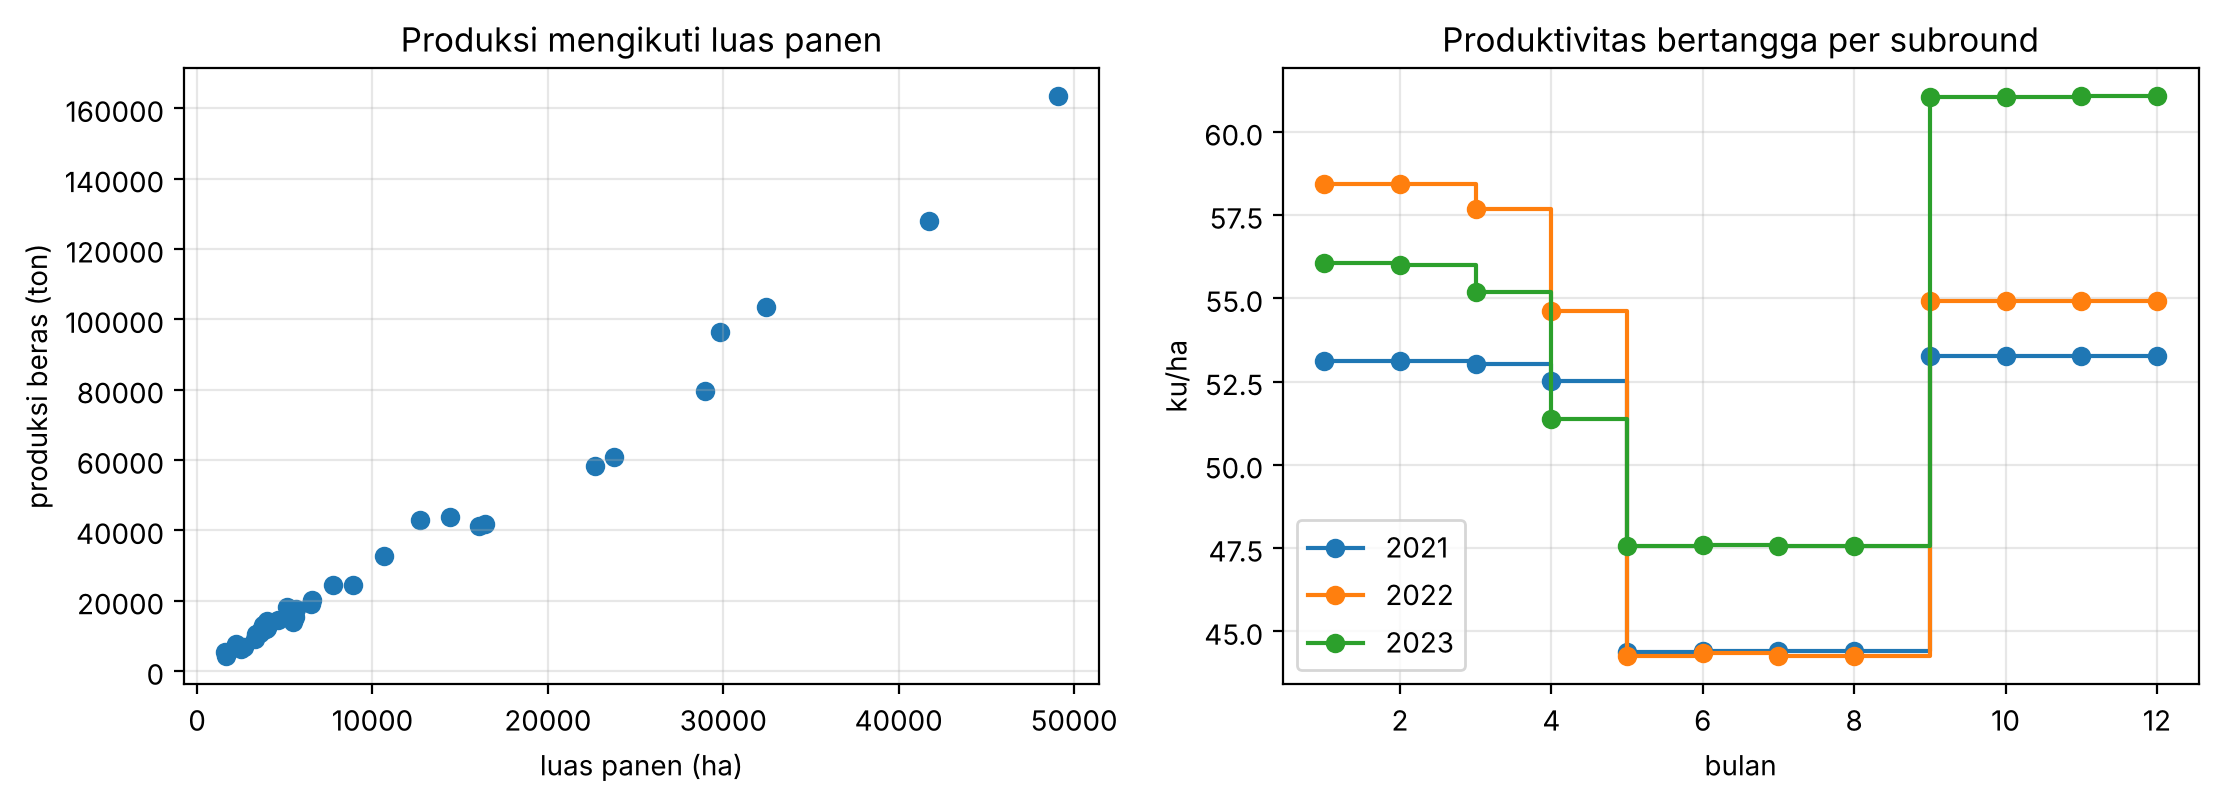

In [3]:
print("Korelasi ln P dan ln L:", round(np.corrcoef(lnP, lnL)[0, 1], 4))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(L, P); ax[0].set(xlabel="luas panen (ha)", ylabel="produksi beras (ton)", title="Produksi mengikuti luas panen")
for th, d in df.groupby("Tahun"):
    ax[1].step(d.Bulan_No, d.Produksi_Gabah_Ton * 10 / d.Luas_Panen_Ha, where="post", label=th, marker="o")
ax[1].set(xlabel="bulan", ylabel="ku/ha", title="Produktivitas bertangga per subround"); ax[1].legend(); plt.show()

## 1. Identifikasi
### 1a. Plot deret dan beda musiman $(1-B^{12})$

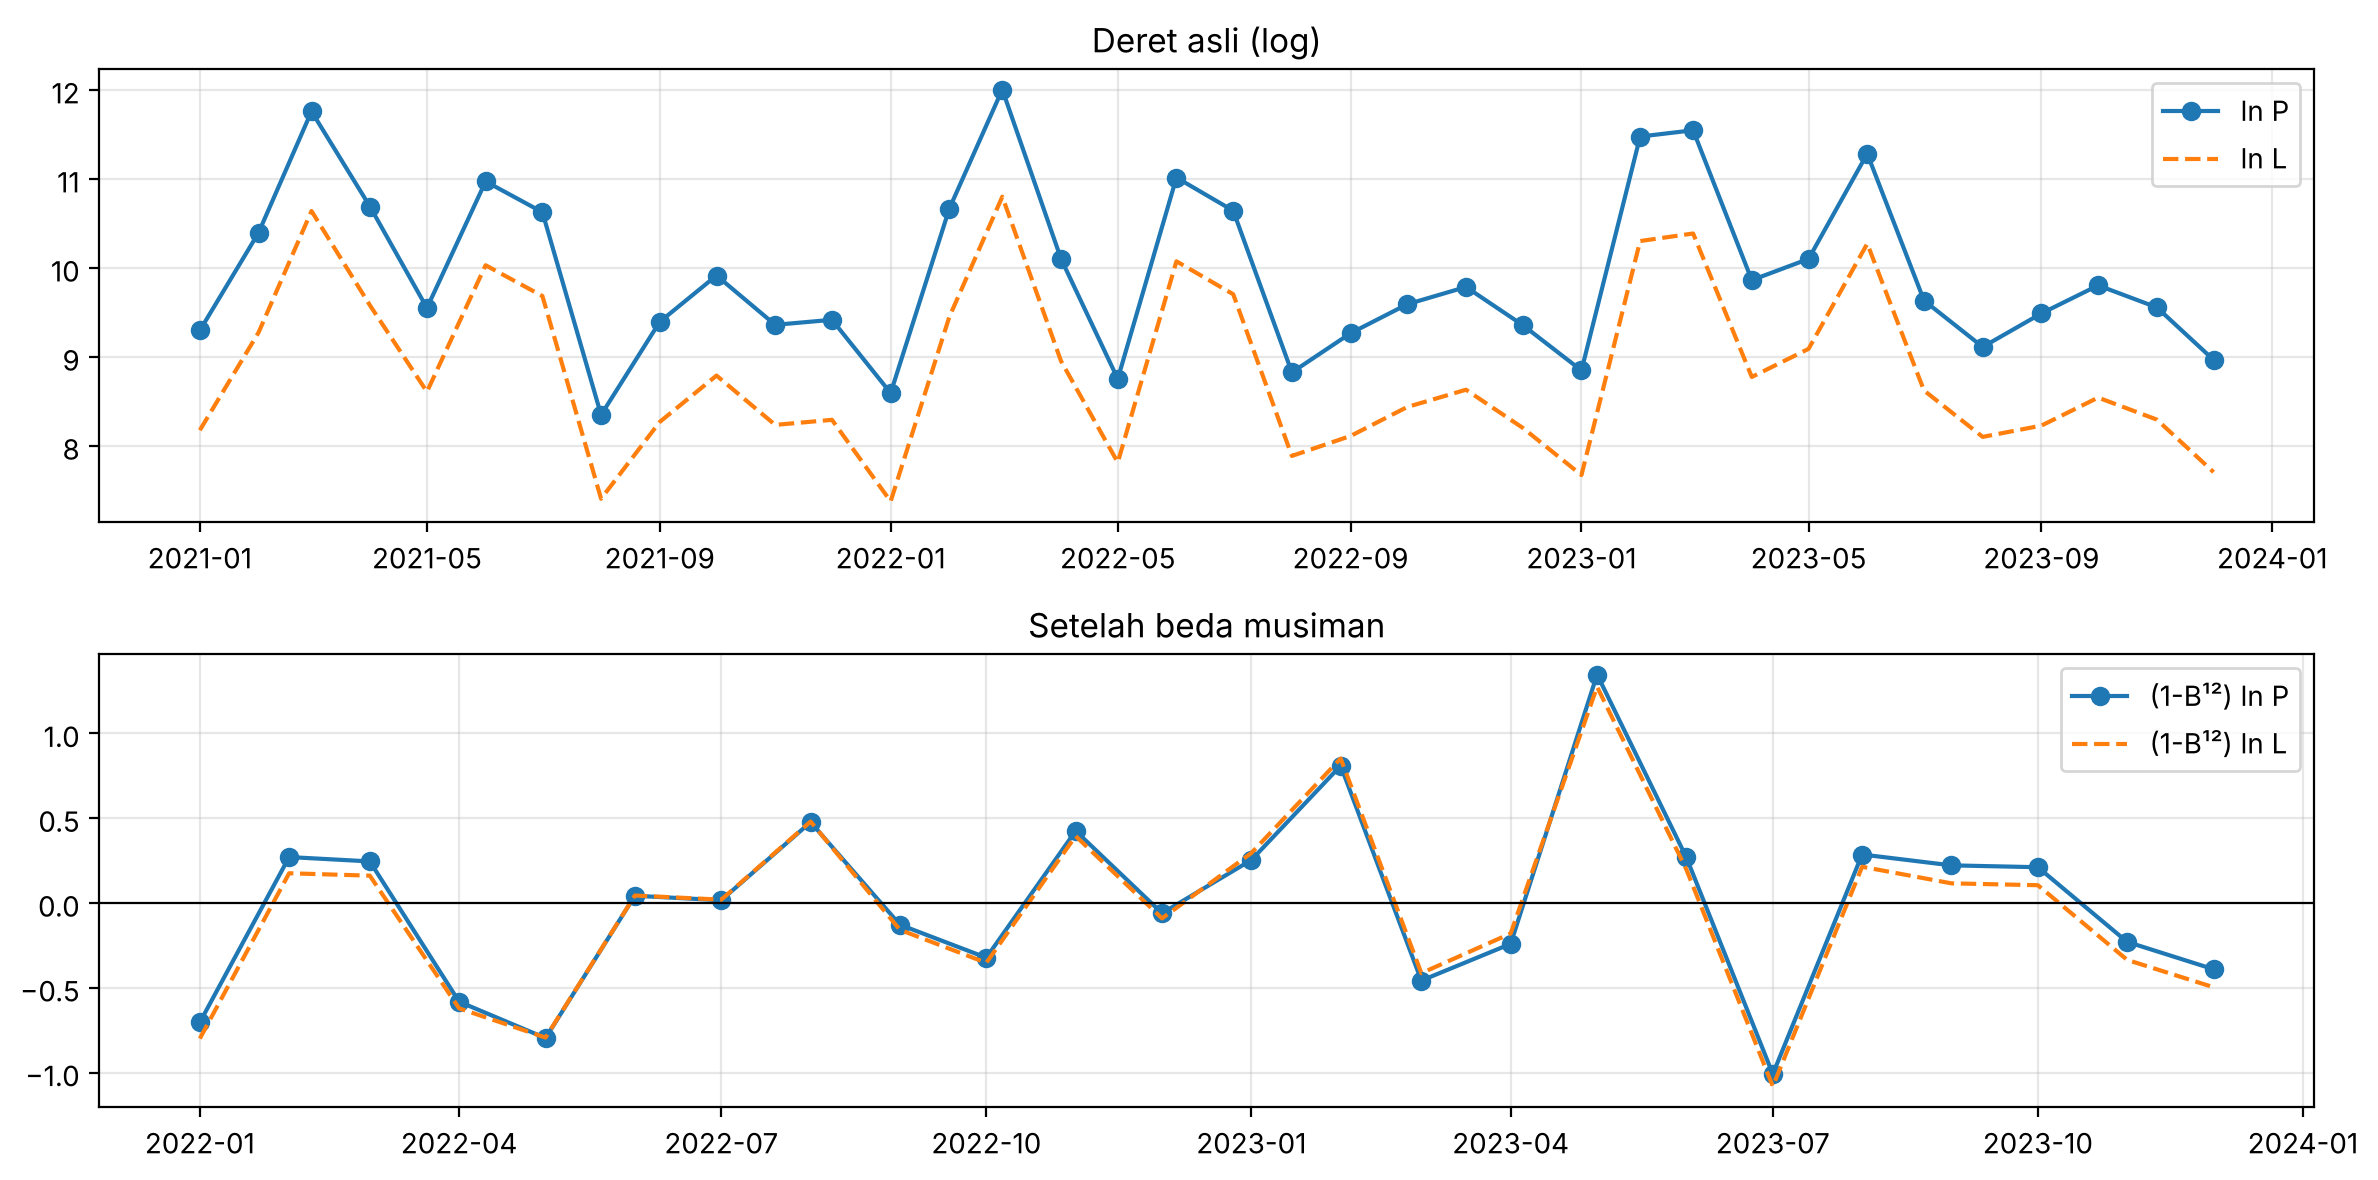

In [4]:
dP, dL = (lnP - lnP.shift(12)).dropna(), (lnL - lnL.shift(12)).dropna()
fig, ax = plt.subplots(2, 1, figsize=(12, 6))
ax[0].plot(lnP, marker="o", label="ln P"); ax[0].plot(lnL, "--", label="ln L"); ax[0].legend(); ax[0].set_title("Deret asli (log)")
ax[1].plot(dP, marker="o", label="(1-B¹²) ln P"); ax[1].plot(dL, "--", label="(1-B¹²) ln L"); ax[1].axhline(0, c="k", lw=.8)
ax[1].legend(); ax[1].set_title("Setelah beda musiman"); plt.tight_layout(); plt.show()

### 1b. Uji stasioneritas
ADF: H₀ tidak stasioner. KPSS: H₀ stasioner.

In [5]:
def uji(x):
    a = adfuller(x, autolag="AIC")[1]
    k = kpss(x, regression="c", nlags="auto")[1]
    return pd.Series({"n": len(x), "ADF p": round(a, 4), "KPSS p": round(k, 3),
                      "stasioner": (a < .05) and (k > .05)})
pd.DataFrame({"ln P": uji(lnP), "(1-B¹²) ln P": uji(dP), "ln L": uji(lnL), "(1-B¹²) ln L": uji(dL)}).T

,n,ADF p,KPSS p,stasioner
ln P,36,0.0004,0.1,True
(1-B¹²) ln P,24,0.0,0.076,True
ln L,36,0.0008,0.1,True
(1-B¹²) ln L,24,0.0,0.042,False


### 1c. ACF dan PACF

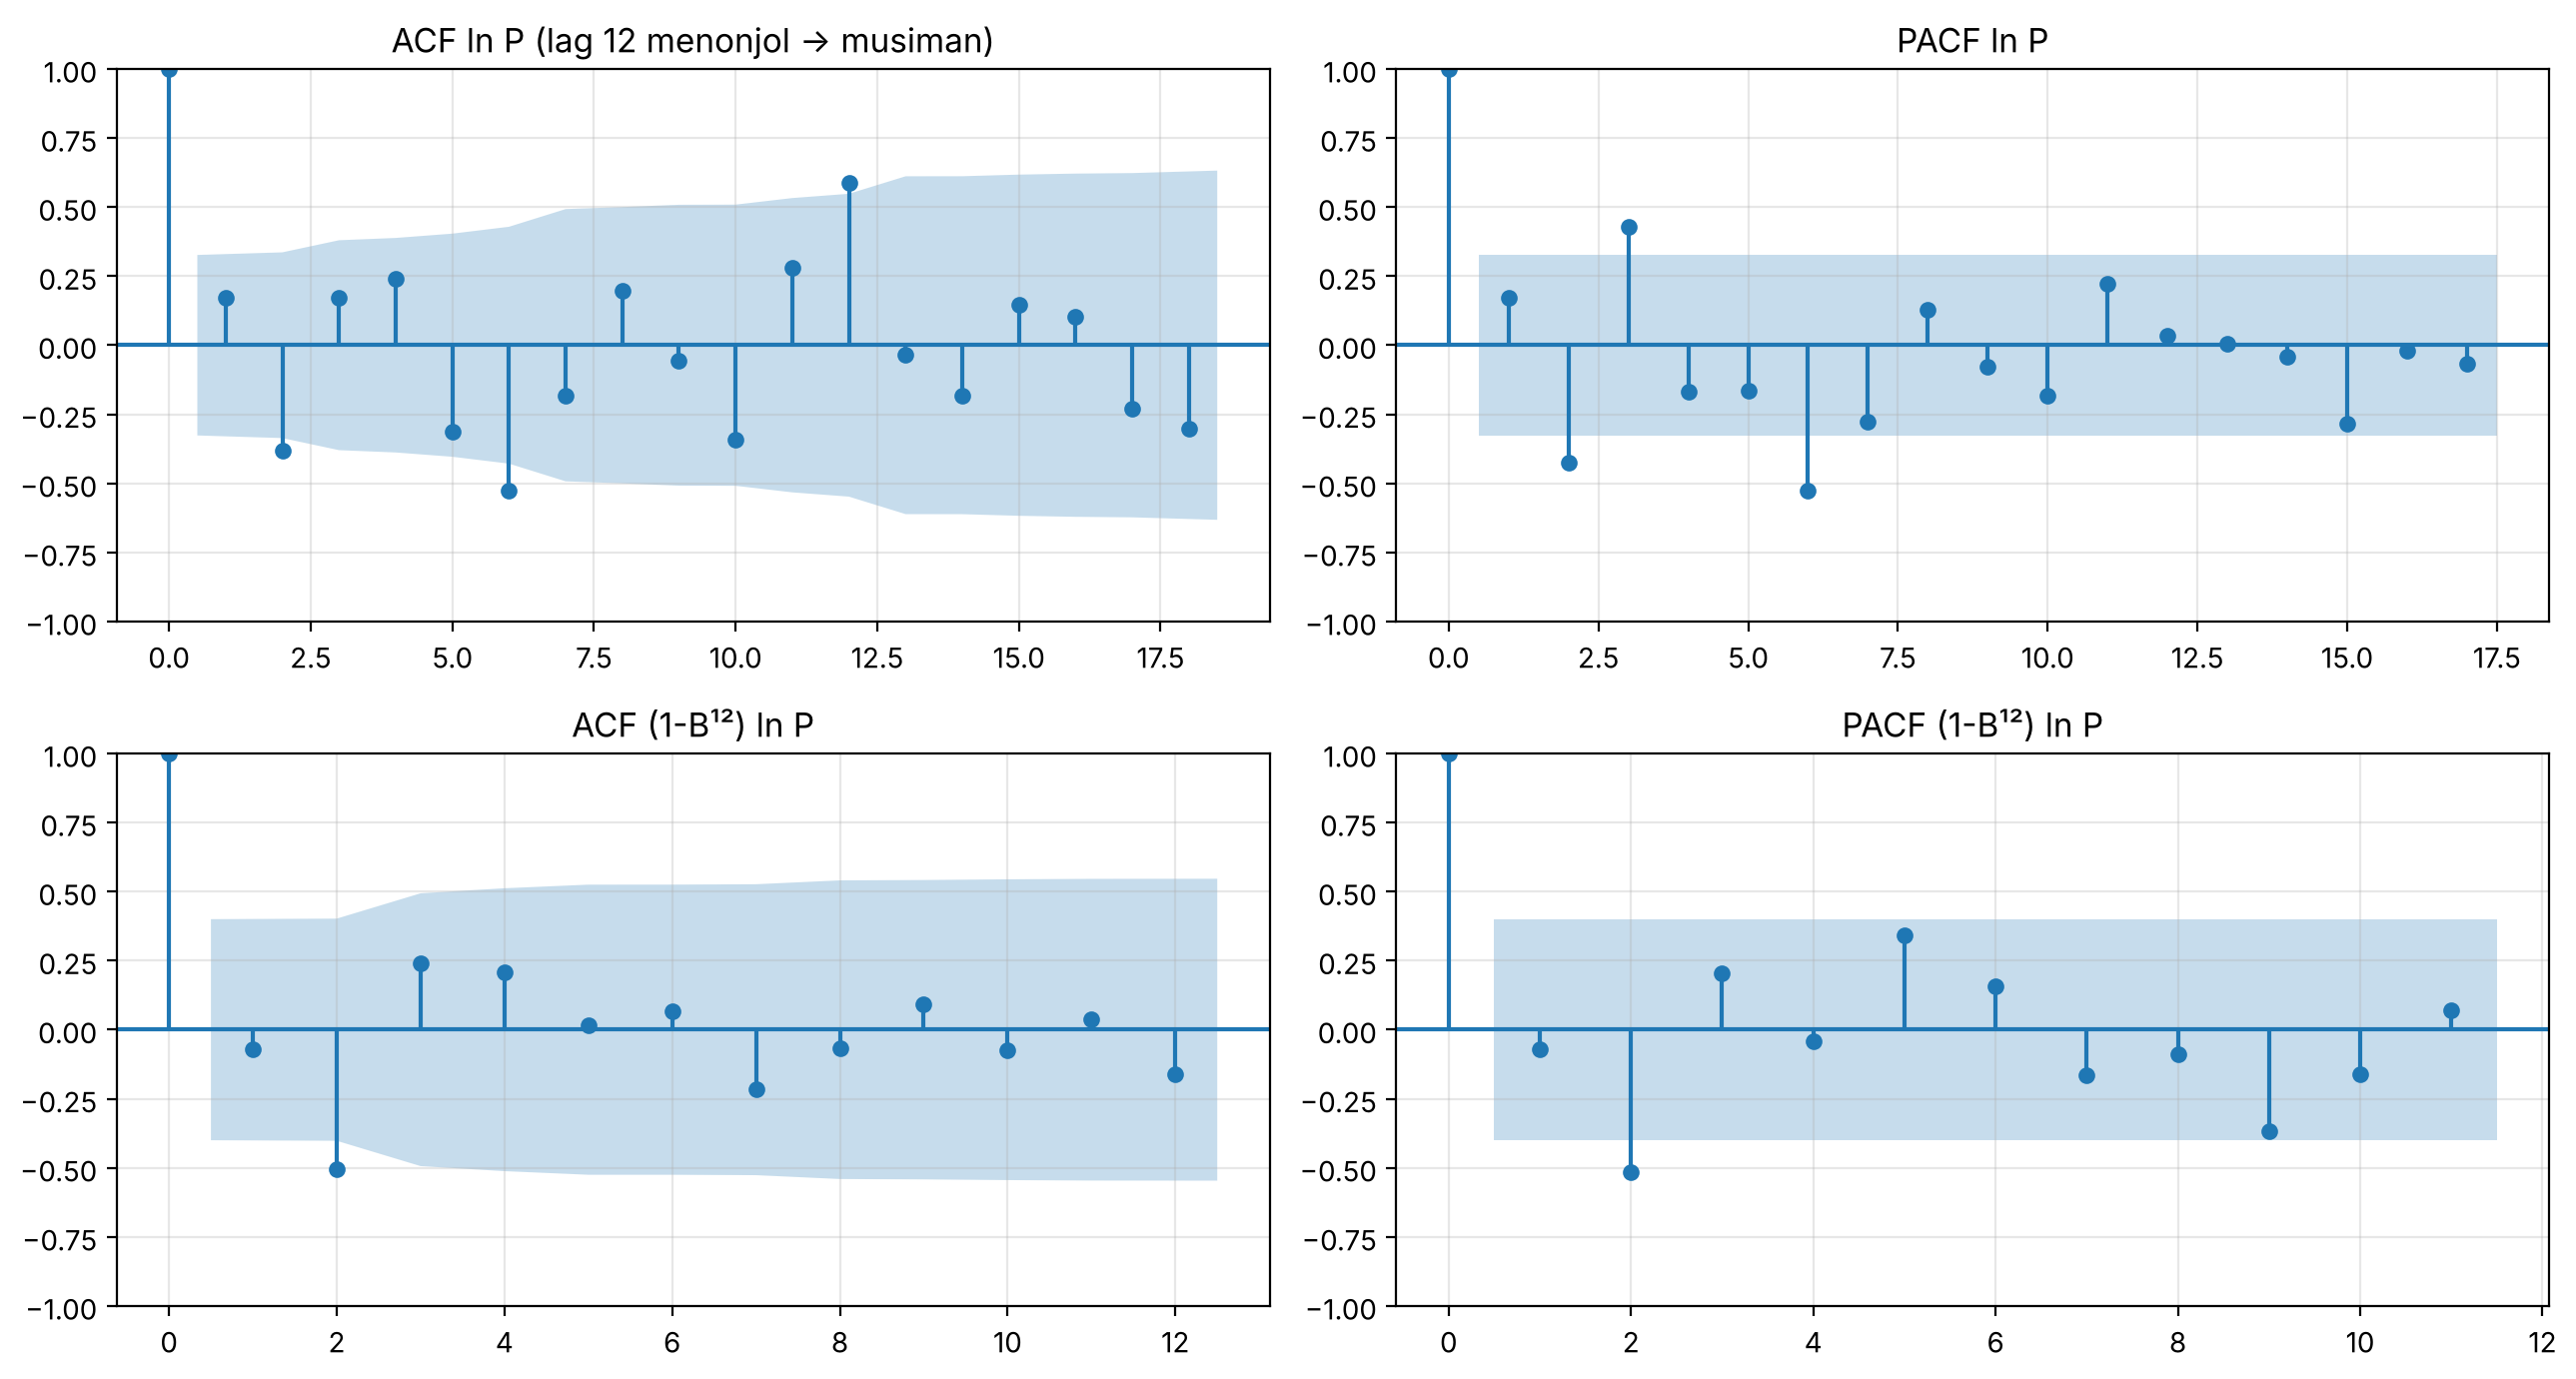

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(lnP, lags=18, ax=ax[0, 0], title="ACF ln P (lag 12 menonjol → musiman)")
plot_pacf(lnP, lags=17, ax=ax[0, 1], method="ywm", title="PACF ln P")
plot_acf(dP, lags=12, ax=ax[1, 0], title="ACF (1-B¹²) ln P")
plot_pacf(dP, lags=11, ax=ax[1, 1], method="ywm", title="PACF (1-B¹²) ln P")
plt.tight_layout(); plt.show()

**Keputusan:** s = 12 (data bulanan), **D = 1** (ACF lag 12 ln P besar), **d = 0** (tidak ada tren dan deret beda musiman
sudah stasioner). Lag 2 menonjol setelah beda musiman, jadi orde biasa kecil. Kandidat dipilih dengan AIC pada tahap berikutnya.

## 2. Estimasi dan seleksi model
Semua kombinasi p, q ∈ {0,1,2}, P, Q ∈ {0,1}. Dipilih AIC terkecil dengan seluruh parameter signifikan dan residual lolos Ljung-Box.

In [7]:
def kandidat(y, exog=None, tambahan=()):
    daftar = [((p, 0, q), (Pp, 1, Q)) for p, q, Pp, Q in itertools.product([0, 1, 2], [0, 1, 2], [0, 1], [0, 1])] + list(tambahan)
    baris = []
    for o, so in daftar:
        m = SARIMAX(y, exog=exog, order=o, seasonal_order=so + (12,)).fit(disp=False)
        pv = m.pvalues.drop("sigma2")
        lb = acorr_ljungbox(m.resid[12:], lags=[6], return_df=True).lb_pvalue.iloc[0]
        baris.append(dict(order=o, sorder=so, AIC=round(m.aic, 2), BIC=round(m.bic, 2), LjungBox_p=round(lb, 3),
                          semua_signifikan=bool((pv < .05).all()) if len(pv) else True, k=len(m.params)))
    return pd.DataFrame(baris).sort_values("AIC").reset_index(drop=True)

def terbaik(t):
    ok = t[t.semua_signifikan & (t.LjungBox_p > .05) & (t.k > 1)]
    return ok.iloc[0]

kand_P = kandidat(lnP, exog=lnL)
best_P = terbaik(kand_P)
print("Model produksi terpilih:", best_P.order, best_P.sorder)
kand_P.head(10)

Model produksi terpilih: (1, 0, 0) (0, 1, 0)


,order,sorder,AIC,BIC,LjungBox_p,semua_signifikan,k
0,"(1, 0, 0)","(0, 1, 0)",-86.83,-83.30,0.616,True,3
1,"(1, 0, 2)","(0, 1, 0)",-86.71,-80.82,0.743,False,5
2,"(2, 0, 2)","(0, 1, 0)",-86.34,-79.27,0.923,False,6
3,"(1, 0, 0)","(1, 1, 0)",-85.69,-80.98,0.694,False,4
4,"(1, 0, 0)","(0, 1, 1)",-85.45,-80.74,0.676,False,4
5,"(2, 0, 0)","(0, 1, 0)",-84.95,-80.24,0.669,False,4
6,"(1, 0, 1)","(0, 1, 0)",-84.91,-80.19,0.659,False,4
7,"(1, 0, 2)","(1, 1, 0)",-84.83,-77.76,0.743,False,6
8,"(1, 0, 2)","(0, 1, 1)",-84.73,-77.66,0.744,False,6
9,"(1, 0, 0)","(1, 1, 1)",-83.78,-77.89,0.692,False,5


In [8]:
kand_L = kandidat(lnL, tambahan=[(([2], 0, 0), (0, 1, 0)), (([2], 0, 0), (1, 1, 0)), (([2], 0, 0), (0, 1, 1))])
best_L = terbaik(kand_L)
print("Model luas panen terpilih:", best_L.order, best_L.sorder, " ([2] = hanya lag 2)")
kand_L.head(10)

Model luas panen terpilih: ([2], 0, 0) (0, 1, 0)  ([2] = hanya lag 2)


,order,sorder,AIC,BIC,LjungBox_p,semua_signifikan,k
0,"(2, 0, 2)","(1, 1, 0)",33.23,40.30,0.455,False,6
1,"(2, 0, 2)","(0, 1, 1)",33.80,40.87,0.465,False,6
2,"([2], 0, 0)","(0, 1, 0)",35.01,37.36,0.530,True,2
3,"(2, 0, 2)","(1, 1, 1)",35.22,43.46,0.466,False,7
4,"([2], 0, 0)","(1, 1, 0)",36.34,39.87,0.321,False,3
5,"([2], 0, 0)","(0, 1, 1)",36.34,39.88,0.324,False,3
6,"(2, 0, 1)","(0, 1, 0)",36.64,41.35,0.902,False,4
7,"(2, 0, 0)","(0, 1, 1)",36.78,41.49,0.607,False,4
8,"(2, 0, 0)","(1, 1, 0)",36.79,41.50,0.657,False,4
9,"(2, 0, 1)","(1, 1, 0)",36.81,42.70,0.902,False,5


### Estimasi model final

In [9]:
m_P = SARIMAX(lnP, exog=lnL, order=best_P.order, seasonal_order=best_P.sorder + (12,)).fit(disp=False)
m_L = SARIMAX(lnL, order=best_L.order, seasonal_order=best_L.sorder + (12,)).fit(disp=False)
print(m_P.summary().tables[1]); print(m_L.summary().tables[1])
beta = m_P.params.iloc[0]
print(f"beta = {beta:.3f}: luas panen naik 1% → produksi naik sekitar {beta:.2f}%")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
0              1.0131      0.012     86.118      0.000       0.990       1.036
ar.L1          0.9097      0.171      5.318      0.000       0.574       1.245
sigma2         0.0011      0.000      3.286      0.001       0.000       0.002
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L2         -0.4824      0.237     -2.035      0.042      -0.947      -0.018
sigma2         0.2085      0.080      2.596      0.009       0.051       0.366
beta = 1.013: luas panen naik 1% → produksi naik sekitar 1.01%


## 3. Diagnosis residual
12 residual pertama dibuang (d + Ds = 12).

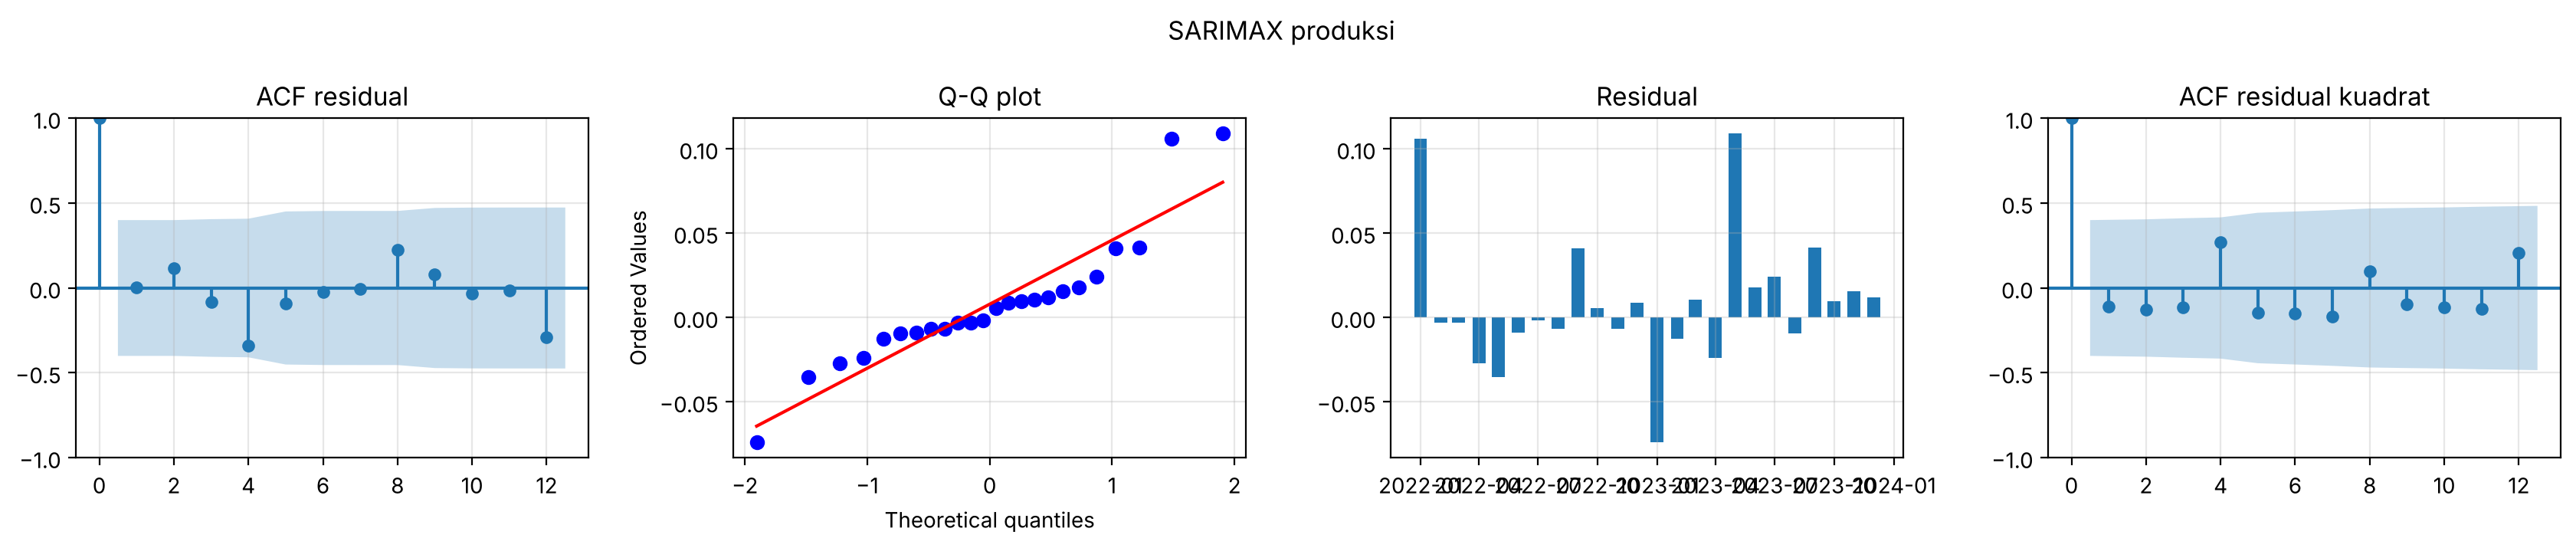

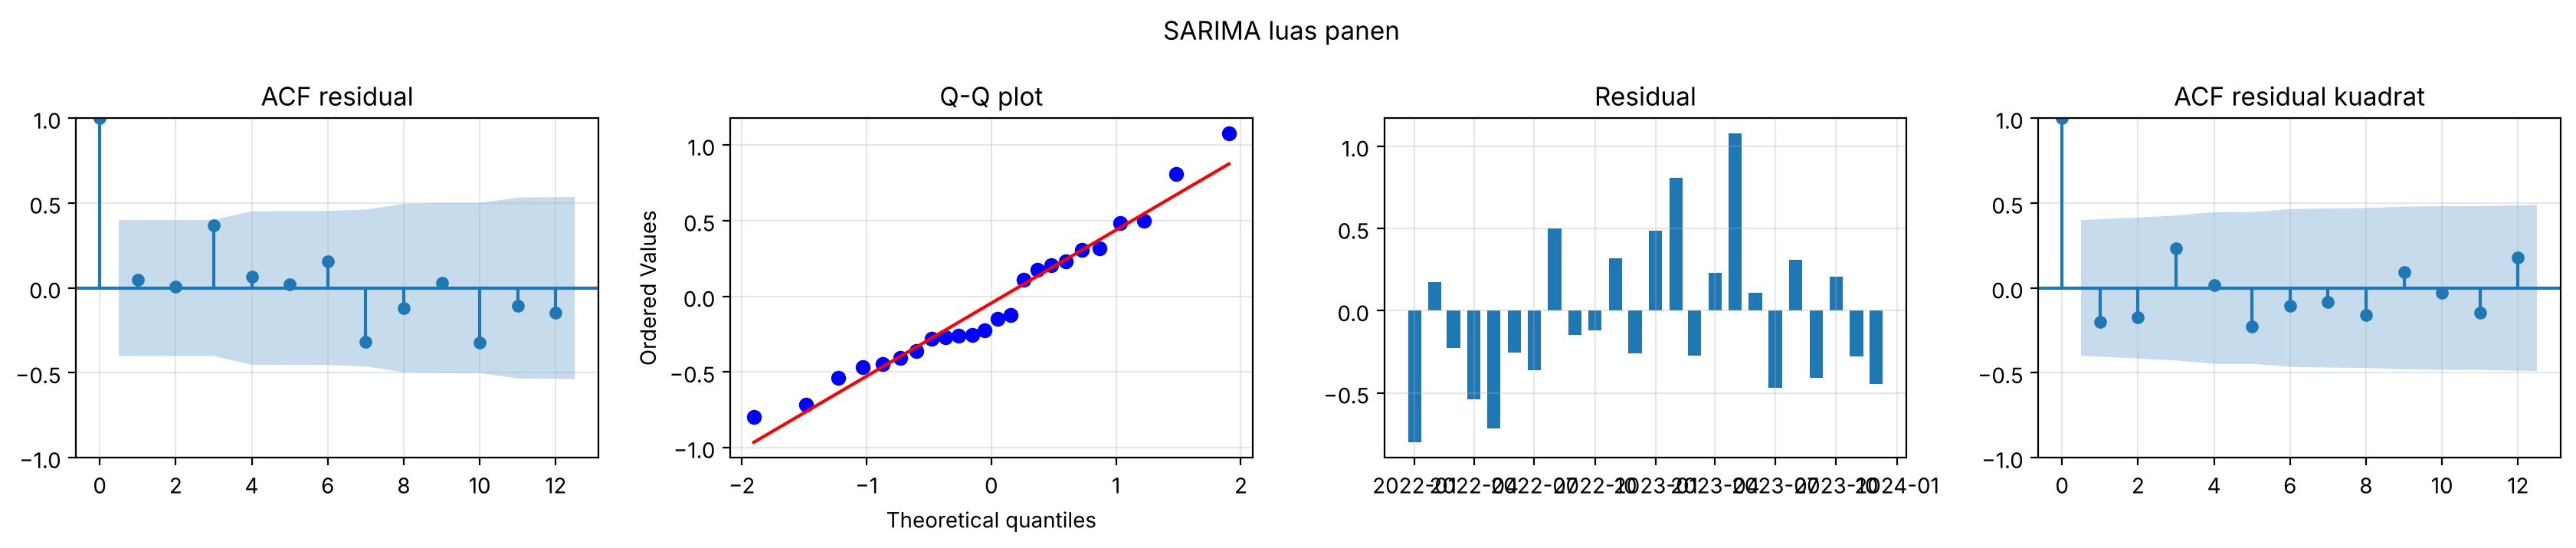

,SARIMAX produksi,SARIMA luas panen
Ljung-Box lag 6 p,0.6160,0.5302
Ljung-Box lag 12 p,0.5196,0.2066
Shapiro-Wilk p,0.0081,0.4018
Jarque-Bera p,0.0239,0.4997
ARCH-LM p,0.5309,0.6860


In [10]:
def diagnosis(m, judul):
    r = m.resid[12:]
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
    plot_acf(r, lags=12, ax=ax[0], title="ACF residual")
    stats.probplot(r, dist="norm", plot=ax[1]); ax[1].set_title("Q-Q plot")
    ax[2].bar(r.index, r.values, width=20); ax[2].set_title("Residual")
    plot_acf(r ** 2, lags=12, ax=ax[3], title="ACF residual kuadrat")
    fig.suptitle(judul); plt.tight_layout(); plt.show()
    lb = acorr_ljungbox(r, lags=[6, 12], return_df=True)
    return pd.Series({"Ljung-Box lag 6 p": lb.lb_pvalue.iloc[0], "Ljung-Box lag 12 p": lb.lb_pvalue.iloc[1],
                      "Shapiro-Wilk p": stats.shapiro(r).pvalue, "Jarque-Bera p": stats.jarque_bera(r).pvalue,
                      "ARCH-LM p": het_arch(r, nlags=4)[1]}).round(4)
pd.DataFrame({"SARIMAX produksi": diagnosis(m_P, "SARIMAX produksi"), "SARIMA luas panen": diagnosis(m_L, "SARIMA luas panen")})

Residual model produksi tidak berautokorelasi (Ljung-Box) dan tanpa efek ARCH, sehingga layak untuk meramal.
Normalitas tidak terpenuhi karena residual besar di awal subround ketika produktivitas BPS berganti, jadi rentang ramalan dibaca sebagai perkiraan.

## 4. Uji ramalan 2023 (ex post dan ex ante)
Model dilatih dengan 2021–2022, lalu meramal 2023.

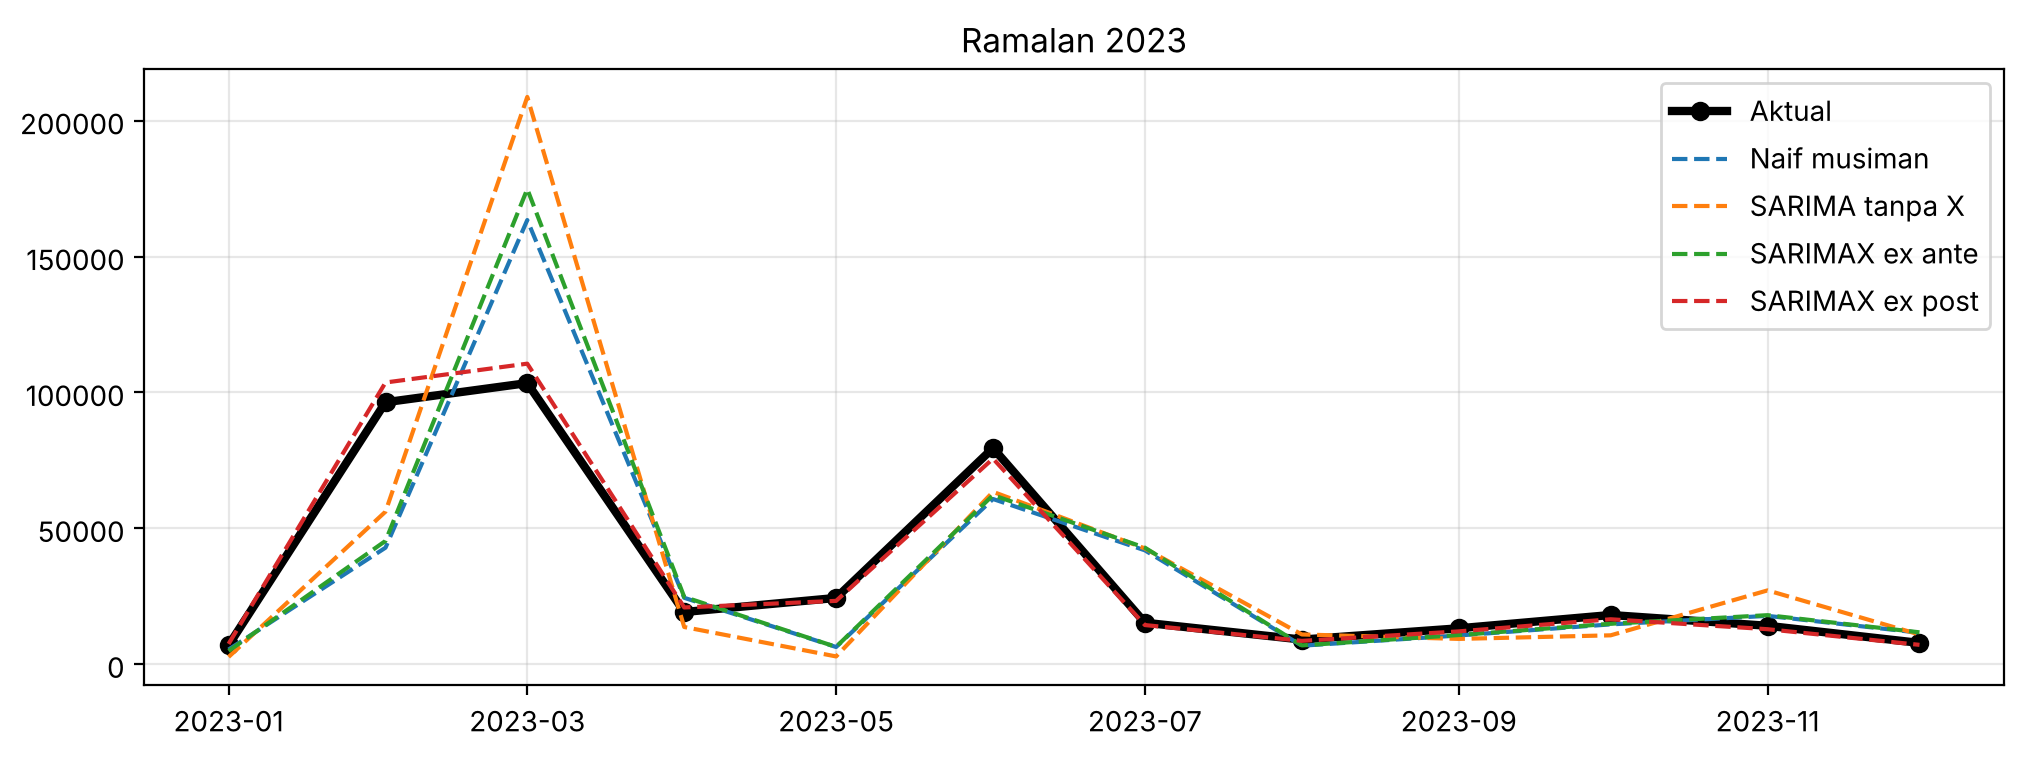

,MAE,RMSE,MAPE %
Naif musiman,16619.8,25704.4,47.7
SARIMA tanpa X,20802.0,34731.7,62.0
SARIMAX ex ante,17385.5,27647.2,49.5
SARIMAX ex post,2298.0,3291.2,7.2


In [11]:
tr, te = slice(0, 24), slice(24, 36)
aktual = P.iloc[te].values
mp = SARIMAX(lnP.iloc[tr], exog=lnL.iloc[tr], order=best_P.order, seasonal_order=best_P.sorder + (12,)).fit(disp=False)
ml = SARIMAX(lnL.iloc[tr], order=best_L.order, seasonal_order=best_L.sorder + (12,)).fit(disp=False)
mu = SARIMAX(lnP.iloc[tr], order=(2, 0, 0), seasonal_order=(1, 1, 0, 12)).fit(disp=False)
ramalan = {
    "Naif musiman": P.iloc[12:24].values,
    "SARIMA tanpa X": np.exp(mu.get_forecast(12).predicted_mean.values),
    "SARIMAX ex ante": np.exp(mp.get_forecast(12, exog=ml.get_forecast(12).predicted_mean.values.reshape(-1, 1)).predicted_mean.values),
    "SARIMAX ex post": np.exp(mp.get_forecast(12, exog=lnL.iloc[te].values.reshape(-1, 1)).predicted_mean.values),
}
ev = pd.DataFrame({k: {"MAE": np.mean(abs(aktual - v)), "RMSE": np.sqrt(np.mean((aktual - v) ** 2)),
                       "MAPE %": np.mean(abs(aktual - v) / aktual) * 100} for k, v in ramalan.items()}).T.round(1)
plt.plot(P.index[te], aktual, "k-o", lw=3, label="Aktual")
for k, v in ramalan.items(): plt.plot(P.index[te], v, "--", label=k)
plt.legend(); plt.title("Ramalan 2023"); plt.show()
ev

## 5. Peramalan 2024 dan peluang defisit

In [12]:
h = 12
fl = m_L.get_forecast(h)                                  # 1) ramal X
fp = m_P.get_forecast(h, exog=fl.predicted_mean.values.reshape(-1, 1))   # 2) masukkan X ke SARIMAX
var = fp.var_pred_mean.values + beta ** 2 * fl.var_pred_mean.values      # 3) gabungkan ketidakpastian
mu_, sd = fp.predicted_mean.values, np.sqrt(var)
drift = K.diff().mean()                                   # konsumsi: ARIMA(0,1,0) dengan drift
kons = K.iloc[-1] + drift * np.arange(1, h + 1)
peluang = stats.norm.cdf((np.log(kons) - mu_) / sd) * 100
proyeksi = pd.DataFrame({
    "Luas_panen_ha": np.exp(fl.predicted_mean.values), "Produksi_ton": np.exp(mu_),
    "Bawah_95": np.exp(mu_ - 1.96 * sd), "Atas_95": np.exp(mu_ + 1.96 * sd),
    "Konsumsi_ton": kons, "Surplus_ton": np.exp(mu_) - kons, "Peluang_defisit_%": peluang,
}, index=fl.predicted_mean.index.strftime("%b %Y")).round(1)
proyeksi["Kategori"] = pd.cut(proyeksi["Peluang_defisit_%"], [-1, 20, 50, 101], labels=["Aman", "Waspada", "Rawan"])
print("Total produksi 2024:", round(proyeksi.Produksi_ton.sum()), "ton")
proyeksi

Total produksi 2024: 464515 ton


,Luas_panen_ha,Produksi_ton,Bawah_95,Atas_95,Konsumsi_ton,Surplus_ton,Peluang_defisit_%,Kategori
Jan 2024,2529.9,9094.3,3664.2,22571.4,12050.8,-2956.4,72.8,Rawan
Feb 2024,37879.7,134892.2,54242.0,335457.7,12071.5,122820.6,0.0,Aman
Mar 2024,30016.5,104047.1,37818.4,286257.3,12092.3,91954.8,0.0,Aman
Apr 2024,5771.0,18463.6,6702.9,50859.7,12113.1,6350.5,20.7,Waspada
May 2024,9222.8,27185.1,9647.3,76604.9,12133.9,15051.3,6.3,Aman
Jun 2024,30601.4,89704.2,31807.7,252984.2,12154.6,77549.5,0.0,Aman
Jul 2024,5463.9,15899.0,5605.7,45092.9,12175.4,3723.6,30.8,Waspada
Aug 2024,3217.3,9311.5,3281.3,26424.0,12196.2,-2884.7,69.4,Rawan
Sep 2024,3783.0,13996.0,4924.1,39781.9,12216.9,1779.1,39.9,Waspada
Oct 2024,5205.1,19175.5,6743.7,54524.6,12237.7,6937.8,20.0,Aman


### Contoh hitungan manual Januari 2024
Hasilnya harus sama dengan baris pertama tabel di atas.

In [13]:
n = len(lnP)
phi1, phi2 = m_P.params["ar.L1"], m_L.params["ar.L2"]
W = lnL - lnL.shift(12)
lnL_hat = lnL.iloc[n - 12] + phi2 * W.iloc[n - 2]         # ln L̂ = ln L(t-11) + φ2·W(t-1)
u = lnP - beta * lnL
Z = u - u.shift(12)
u_hat = u.iloc[n - 12] + phi1 * Z.iloc[n - 1]               # û = u(t-11) + φ1·Z(t)
P_hat = np.exp(beta * lnL_hat + u_hat)
print(f"L̂ = {np.exp(lnL_hat):,.0f} ha,  P̂ = {P_hat:,.0f} ton  (statsmodels: {np.exp(mu_[0]):,.0f})")

L̂ = 2,530 ha,  P̂ = 9,094 ton  (statsmodels: 9,094)


## Simpan hasil

In [14]:
Path("hasil").mkdir(exist_ok=True)
kand_P.to_csv("hasil/kandidat_sarimax_produksi.csv", index=False)
kand_L.to_csv("hasil/kandidat_sarima_luas_panen.csv", index=False)
ev.to_csv("hasil/evaluasi_ramalan_2023.csv")
proyeksi.to_csv("hasil/proyeksi_2024_sarimax.csv")
print("tersimpan di folder hasil/")

tersimpan di folder hasil/
